In [ ]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [ ]:
import pandas as pd
df=pd.read_csv("/content/drive/MyDrive/Cars India Dataset.csv")
df.head()
df.shape


(156, 24)

In [ ]:
df.head()

,Model,Maker,Type,Seats,Displacement,Length,Width,Height,Wheelbase,No_of_Cylinders,...,Rear Brake,Drive,Turning Radius,Fuel Tank Capacity,Boot Space,Fuel Efficiency,Emission Type,Tyre Size,Variants,NCAP Rating
0,Virtus,Volkswagen,Sedan,5,999.0,4561,1752,1507,2651,3.0,...,Drum,2WD,5.05,45.0,521.0,19.40,BS VI,205/55 R16,3,Not Tested
1,Virtus,Volkswagen,Sedan,5,999.0,4561,1752,1507,2651,3.0,...,Drum,2WD,5.05,45.0,521.0,18.12,BS VI,205/55 R16,2,Not Tested
2,Virtus,Volkswagen,Sedan,5,1498.0,4561,1752,1507,2651,4.0,...,Drum,2WD,5.05,45.0,521.0,18.67,BS VI,205/55 R16,1,Not Tested
3,Taigun,Volkswagen,Mid Size SUV,5,999.0,4221,1760,1612,2651,3.0,...,Drum,2WD,5.05,50.0,385.0,19.20,BS VI,205/55 R17,3,5
4,Taigun,Volkswagen,Mid Size SUV,5,999.0,4221,1760,1612,2651,3.0,...,Drum,2WD,5.05,50.0,385.0,17.23,BS VI,205/55 R17,2,5


In [ ]:
df.shape

(156, 24)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 156 entries, 0 to 155
Data columns (total 24 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Model               156 non-null    object 
 1   Maker               156 non-null    object 
 2   Type                156 non-null    object 
 3   Seats               156 non-null    int64  
 4   Displacement        155 non-null    float64
 5   Length              156 non-null    int64  
 6   Width               156 non-null    int64  
 7   Height              156 non-null    int64  
 8   Wheelbase           156 non-null    int64  
 9   No_of_Cylinders     155 non-null    float64
 10  Fuel                156 non-null    object 
 11  Engine Type         156 non-null    object 
 12  Transmission        155 non-null    object 
 13  Front Brake         156 non-null    object 
 14  Rear Brake          156 non-null    object 
 15  Drive               156 non-null    object 
 16  Turning 

In [ ]:
df.isnull().sum()

,0
Model,0
Maker,0
Type,0
Seats,0
Displacement,1
Length,0
Width,0
Height,0
Wheelbase,0
No_of_Cylinders,1


In [ ]:
df.isnull().sum().sum()

np.int64(62)

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.drop_duplicates(inplace=True)

In [ ]:
print("Duplicates after removal:", df.duplicated().sum())

Duplicates after removal: 0


In [ ]:
import numpy as np
numeric_columns = df.select_dtypes(include=np.number).columns
categorical_columns = df.select_dtypes(include='object').columns

for col in numeric_columns:
    df[col] = df[col].fillna(df[col].median())
for col in categorical_columns:
    df[col] = df[col].fillna(df[col].mode()[0])

In [ ]:
df.isnull().sum().sum()

np.int64(0)

In [ ]:
for col in categorical_columns:
    print("\n", col)
    print(df[col].unique())


 Model
['Virtus' 'Taigun' 'Tiguan' 'Amaze' 'City 5th Gen' 'City e-HEV'
 'City 4th Gen' 'WR-V' 'Jazz' 'Kicks' 'GT-R' 'Magnite' 'Kiger' 'Triber'
 'Kwid' 'C3' 'C5 Aircross' 'Scorpio-N' 'Scorpio Classic' 'Marazzo'
 'XUV 300' 'XUV 700' 'Thar AX OPT' 'Thar LX' 'Urban Cruiser'
 'Fortuner Legender' 'Fortuner' 'Glanza' 'Grand i10 Nios' 'i20'
 'i20 N-Line' 'Verna' 'Aura' 'Tucson' 'Kona Electric' 'Venue'
 'Venue N-Line' 'Creta' 'Alcazar' 'Sonet' 'Seltos' 'Carnival' 'Carens'
 'Harrier' 'Safari']

 Maker
['Volkswagen' 'Honda' 'Nissan' 'Renault' 'Citroen' 'Mahindra' 'Toyota'
 'Hyundai' 'Kia' 'Tata']

 Type
['Sedan' 'Mid Size SUV' 'SUV' 'Compact Sedan' 'Compact SUV' 'Hatchback'
 'Sports Car' 'MUV' 'MPV']

 Fuel
['Petrol' 'Diesel' 'Petrol Hybrid' 'Petrol + CNG' 'Electric']

 Engine Type
['1.0L TSI' '1.5L TSI Evo with ACT' '2L TSI In-Line' 'SOHC i-VTEC'
 'DOHC i-DTEC' 'i-VTEC DOHC with VTC'
 'Atkinson cycle i-VTEC DOHC with VTC' 'HR 13DDT' 'HR 15' 'VR38DETT'
 'B4D 1.0L NA' 'HRAO 1.0L Turbo' '1.0L Turb

In [ ]:
df_encoded = pd.get_dummies(df, drop_first=True)
df_encoded.head()

,Seats,Displacement,Length,Width,Height,Wheelbase,No_of_Cylinders,Turning Radius,Fuel Tank Capacity,Boot Space,...,Tyre Size_265/60 R18,Tyre Size_265/65 R17,Tyre Size_285/35/20,NCAP Rating_2,NCAP Rating_3,NCAP Rating_4,NCAP Rating_5,NCAP Rating_6,NCAP Rating_Not Rated,NCAP Rating_Not Tested
0,5,999.0,4561,1752,1507,2651,3.0,5.05,45.0,521.0,...,False,False,False,False,False,False,False,False,False,True
1,5,999.0,4561,1752,1507,2651,3.0,5.05,45.0,521.0,...,False,False,False,False,False,False,False,False,False,True
2,5,1498.0,4561,1752,1507,2651,4.0,5.05,45.0,521.0,...,False,False,False,False,False,False,False,False,False,True
3,5,999.0,4221,1760,1612,2651,3.0,5.05,50.0,385.0,...,False,False,False,False,False,False,True,False,False,False
4,5,999.0,4221,1760,1612,2651,3.0,5.05,50.0,385.0,...,False,False,False,False,False,False,True,False,False,False


In [ ]:
df[numeric_columns].describe()
df_clean = df.copy()

for col in numeric_columns:
    Q1 = df_clean[col].quantile(0.25)
    Q3 = df_clean[col].quantile(0.75)
    IQR = Q3 - Q1

    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR

    df_clean = df_clean[
        (df_clean[col] >= lower) &
        (df_clean[col] <= upper)
    ]

In [ ]:
# Final check
print("Final dataset shape:", df_clean.shape)

print("\nMissing values:")
print(df_clean.isnull().sum().sum())

print("\nDuplicate rows:")
print(df_clean.duplicated().sum().sum())

display(df_clean.head())

Final dataset shape: (93, 24)

Missing values:
0

Duplicate rows:
0


,Model,Maker,Type,Seats,Displacement,Length,Width,Height,Wheelbase,No_of_Cylinders,...,Rear Brake,Drive,Turning Radius,Fuel Tank Capacity,Boot Space,Fuel Efficiency,Emission Type,Tyre Size,Variants,NCAP Rating
2,Virtus,Volkswagen,Sedan,5,1498.0,4561,1752,1507,2651,4.0,...,Drum,2WD,5.05,45.0,521.0,18.67,BS VI,205/55 R16,1,Not Tested
10,Amaze,Honda,Compact Sedan,5,1498.0,3995,1695,1501,2470,4.0,...,Drum,2WD,4.90,35.0,420.0,24.70,BS VI,175/65 R15,3,4
11,Amaze,Honda,Compact Sedan,5,1498.0,3995,1695,1501,2470,4.0,...,Drum,2WD,4.90,35.0,420.0,21.00,BS VI,175/65 R15,2,4
12,City 5th Gen,Honda,Sedan,5,1498.0,4549,1748,1489,2600,4.0,...,Drum,2WD,5.30,40.0,506.0,17.80,BS VI,185/55 R16,3,5
13,City 5th Gen,Honda,Sedan,5,1498.0,4549,1748,1489,2600,4.0,...,Drum,2WD,5.30,40.0,506.0,18.40,BS VI,185/55 R16,3,5


In [ ]:
#Saving the Cleaned Dataset
df_clean.to_csv("Cars_India_Cleaned.csv", index=False)

print("Cleaned dataset saved successfully!")

Cleaned dataset saved successfully!


In [ ]:
#Importing Cleaned Dataset
import pandas as pd
df_clean = pd.read_csv("Cars_India_Cleaned.csv")
print(df_clean.shape)
df_clean.head()

(93, 24)


,Model,Maker,Type,Seats,Displacement,Length,Width,Height,Wheelbase,No_of_Cylinders,...,Rear Brake,Drive,Turning Radius,Fuel Tank Capacity,Boot Space,Fuel Efficiency,Emission Type,Tyre Size,Variants,NCAP Rating
0,Virtus,Volkswagen,Sedan,5,1498.0,4561,1752,1507,2651,4.0,...,Drum,2WD,5.05,45.0,521.0,18.67,BS VI,205/55 R16,1,Not Tested
1,Amaze,Honda,Compact Sedan,5,1498.0,3995,1695,1501,2470,4.0,...,Drum,2WD,4.90,35.0,420.0,24.70,BS VI,175/65 R15,3,4
2,Amaze,Honda,Compact Sedan,5,1498.0,3995,1695,1501,2470,4.0,...,Drum,2WD,4.90,35.0,420.0,21.00,BS VI,175/65 R15,2,4
3,City 5th Gen,Honda,Sedan,5,1498.0,4549,1748,1489,2600,4.0,...,Drum,2WD,5.30,40.0,506.0,17.80,BS VI,185/55 R16,3,5
4,City 5th Gen,Honda,Sedan,5,1498.0,4549,1748,1489,2600,4.0,...,Drum,2WD,5.30,40.0,506.0,18.40,BS VI,185/55 R16,3,5


In [ ]:
df_clean.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 93 entries, 0 to 92
Data columns (total 24 columns):
 #   Column              Non-Null Count  Dtype  
---  ------              --------------  -----  
 0   Model               93 non-null     object 
 1   Maker               93 non-null     object 
 2   Type                93 non-null     object 
 3   Seats               93 non-null     int64  
 4   Displacement        93 non-null     float64
 5   Length              93 non-null     int64  
 6   Width               93 non-null     int64  
 7   Height              93 non-null     int64  
 8   Wheelbase           93 non-null     int64  
 9   No_of_Cylinders     93 non-null     float64
 10  Fuel                93 non-null     object 
 11  Engine Type         93 non-null     object 
 12  Transmission        93 non-null     object 
 13  Front Brake         93 non-null     object 
 14  Rear Brake          93 non-null     object 
 15  Drive               93 non-null     object 
 16  Turning Ra

In [ ]:
fuel_comparison = df_clean[
    ["Model", "Maker", "Fuel Efficiency"]
].sort_values(
    by="Fuel Efficiency",
    ascending=False
)

print(fuel_comparison)

           Model    Maker  Fuel Efficiency
53           i20  Hyundai             25.2
58         Verna  Hyundai             25.0
1          Amaze    Honda             24.7
5   City 5th Gen    Honda             24.1
8           WR-V    Honda             23.7
..           ...      ...              ...
70       Alcazar  Hyundai             14.5
74       Alcazar  Hyundai             14.5
75       Alcazar  Hyundai             14.2
71       Alcazar  Hyundai             14.2
13         Kicks   Nissan             13.9

[93 rows x 3 columns]


In [ ]:
manufacturer_analysis = df_clean.groupby("Maker")[
    "Fuel Efficiency"
].mean().sort_values(ascending=False)

print(manufacturer_analysis)

Maker
Toyota        20.270000
Honda         19.730000
Hyundai       19.156970
Volkswagen    18.670000
Mahindra      17.570370
Kia           17.493333
Nissan        15.300000
Name: Fuel Efficiency, dtype: float64


In [ ]:
#engine displacement vs mileage
engine_mileage = df_clean[
    ["Model", "Displacement", "Fuel Efficiency"]
].sort_values(
    by="Displacement"
)
print(engine_mileage)

             Model  Displacement  Fuel Efficiency
55      i20 N-Line         998.0            20.25
48  Grand i10 Nios         998.0            21.00
54      i20 N-Line         998.0            20.25
51             i20         998.0            20.25
60           Verna         998.0            19.20
..             ...           ...              ...
32         XUV 700        2200.0            18.10
33         XUV 700        2200.0            18.10
34         XUV 700        2200.0            18.10
35         XUV 700        2200.0            18.10
31         XUV 700        2200.0            18.10

[93 rows x 3 columns]


In [ ]:
#correlation
correlation = df_clean[
    ["Displacement", "Fuel Efficiency"]
].corr()

print(correlation)

                 Displacement  Fuel Efficiency
Displacement         1.000000        -0.338914
Fuel Efficiency     -0.338914         1.000000


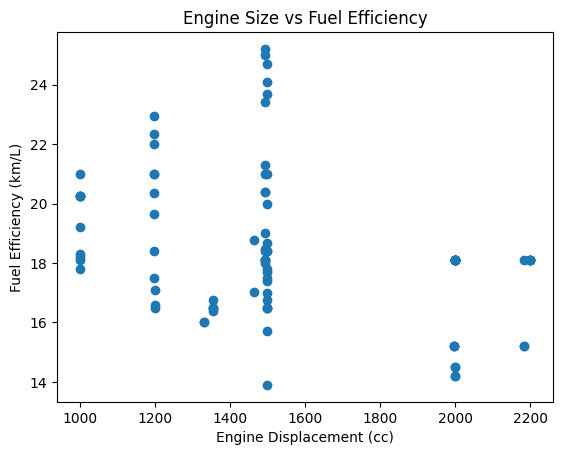

In [ ]:
import matplotlib.pyplot as plt

plt.scatter(df_clean["Displacement"], df_clean["Fuel Efficiency"])

plt.title("Engine Size vs Fuel Efficiency")
plt.xlabel("Engine Displacement (cc)")
plt.ylabel("Fuel Efficiency (km/L)")
plt.show()

Maker
Toyota        20.270000
Honda         19.730000
Hyundai       19.156970
Volkswagen    18.670000
Mahindra      17.570370
Kia           17.493333
Nissan        15.300000
Name: Fuel Efficiency, dtype: float64


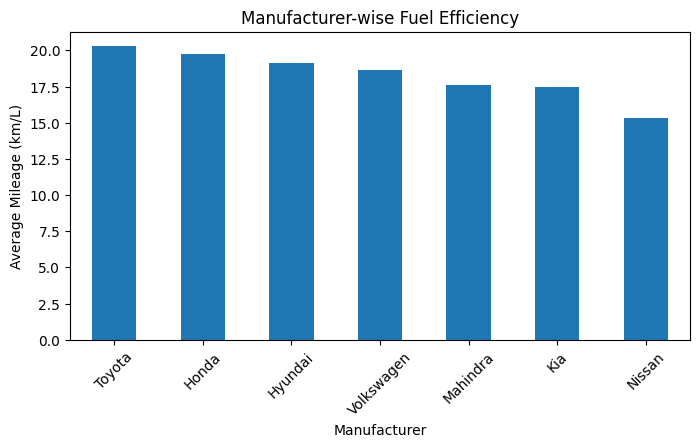

In [ ]:
import matplotlib.pyplot as plt

maker_avg = df_clean.groupby("Maker")["Fuel Efficiency"].mean()

maker_avg = maker_avg.sort_values(ascending=False)

print(maker_avg)

maker_avg.plot(kind="bar", figsize=(8,4))
plt.title("Manufacturer-wise Fuel Efficiency")
plt.xlabel("Manufacturer")
plt.ylabel("Average Mileage (km/L)")
plt.xticks(rotation=45)
plt.show()

In [ ]:
correlation = df_clean["Displacement"].corr(df_clean["Fuel Efficiency"])

print("Correlation:", correlation)

Correlation: -0.3389135689128373


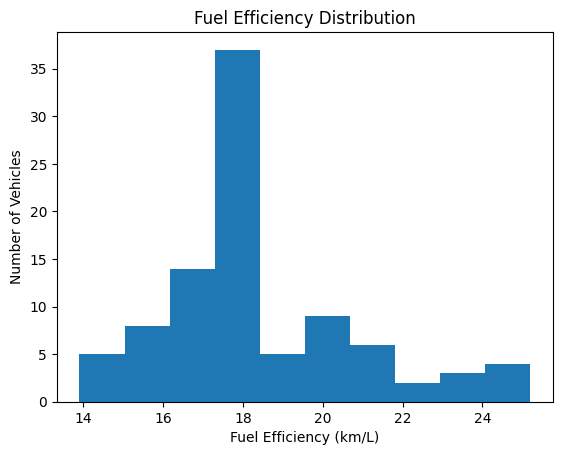

In [ ]:
import matplotlib.pyplot as plt

plt.hist(df_clean["Fuel Efficiency"], bins=10)

plt.title("Fuel Efficiency Distribution")
plt.xlabel("Fuel Efficiency (km/L)")
plt.ylabel("Number of Vehicles")
plt.show()

In [ ]:
fuel_type_analysis = df_clean.groupby("Fuel")["Fuel Efficiency"].agg(
    ["count", "mean", "min", "max"]
)